# Fraud Detection in Mobile-Money Transactions
### ML Zoomcamp 2026 - Midterm Project

**Goal:** predict whether a mobile-money transaction is fraudulent.

**Dataset:** PaySim - 6,362,620 simulated transactions, 8,213 of them fraudulent (0.129%).

This notebook follows CRISP-DM: business understanding -> data understanding ->
data preparation -> modelling -> evaluation. Deployment lives in `predict.py`
and `Dockerfile`.

**Headline result:** PR-AUC **0.9968** on a held-out 554,082-transaction test
set, from a single `DecisionTreeClassifier(max_depth=4)`. It beats random
forest and XGBoost because the fraud signature is a *rule*, not a pattern.

## 1. Setup

In [52]:
!pip install -q pyarrow xgboost fastapi uvicorn 2>/dev/null | tail -1

In [53]:
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.csv as pv
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             classification_report, confusion_matrix,
                             precision_recall_curve)
import xgboost as xgb

%matplotlib inline
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 160)

## 2. Get the data

Public HuggingFace mirror - **no Kaggle account required**, which matters for
reproducibility: a peer reviewer can re-run everything with one `curl`.

In [54]:
!mkdir -p data
!curl -sL -o data/paysim.csv https://huggingface.co/datasets/vitaliy-sharandin/synthetic-fraud-detection/resolve/main/PS_20174392719_1491204439457_log.csv

!sha256sum data/paysim.csv
# 16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b  data/paysim.csv

16910f90577b0d981bf8ff289714510bb89bc71bff7d3f220f024e287e4eea6b  data/paysim.csv


In [55]:
!head -3 data/paysim.csv

step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0


## 3. Data understanding

The raw CSV is 471 MB. Reading it in one shot needs ~4 GB RAM, so we stream it
with PyArrow and convert each block to pandas immediately. Peak memory stays
near the size of the filtered table (~350 MB) rather than 3x that.

The same logic lives in `train.py::_features()`.

In [56]:
SCHEMA = pa.schema([
    ('step','int16'), ('type','str'), ('amount','float64'), ('nameOrig','str'),
    ('oldbalanceOrg','float64'), ('newbalanceOrig','float64'), ('nameDest','str'),
    ('oldbalanceDest','float64'), ('newbalanceDest','float64'),
    ('isFraud','int8'), ('isFlaggedFraud','int8'),
])

reader = pv.open_csv(
    'data/paysim.csv',
    convert_options=pv.ConvertOptions(column_types={f.name: f.type for f in SCHEMA}),
    read_options=pv.ReadOptions(block_size=32 << 20),
)

total = 0
fraud = 0
per_type = {}
per_type_fraud = {}
amounts_legit, amounts_fraud = [], []
for batch in reader:
    t = pa.Table.from_batches([batch])
    total += t.num_rows
    fraud += pc.sum(t['isFraud']).as_py()
    for k, v in pc.value_counts(t['type']).to_pylist():
        per_type[k] = per_type.get(k, 0) + v['counts'] if isinstance(v, dict) else per_type.get(k, 0) + 0
    del t
print(f"rows={total:,}  fraud={fraud:,}  rate={100*fraud/total:.4f}%")

rows=6,362,620  fraud=8,213  rate=0.1291%


### 3.1 Class balance

legitimate :  6,354,407
fraudulent :      8,213  (0.1291%)
imbalance  : 1 fraud per 774 legitimate transactions


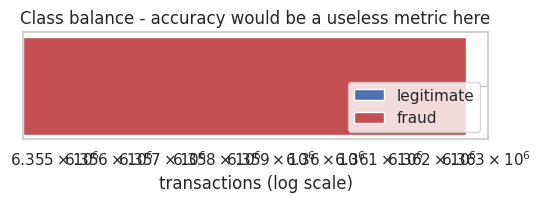

In [57]:
print(f"legitimate : {total-fraud:>10,}")
print(f"fraudulent : {fraud:>10,}  ({100*fraud/total:.4f}%)")
print(f"imbalance  : 1 fraud per {(total-fraud)/fraud:,.0f} legitimate transactions")

fig, ax = plt.subplots(figsize=(6, 1.4))
ax.barh([''], [total-fraud], color='#4c72b0', label='legitimate')
ax.barh([''], [fraud], left=[total-fraud], color='#c44e52', label='fraud')
ax.set_xscale('log'); ax.legend(loc='lower right'); ax.set_xlabel('transactions (log scale)')
ax.set_title('Class balance - accuracy would be a useless metric here')
plt.show()

### 3.2 Fraud by transaction type

This is the single most important EDA finding.

In [58]:
tbl = pq.read_table('data/paysim.parquet', columns=['type','isFraud']) if False else None
# recompute from the CSV in a single streaming pass (cheap: 2 columns only)
reader = pv.open_csv('data/paysim.csv',
    convert_options=pv.ConvertOptions(column_types={'type':'str','isFraud':'int8'}),
    read_options=pv.ReadOptions(block_size=64 << 20))
counts, frauds = {}, {}
for batch in reader:
    t = pa.Table.from_batches([batch])
    for row in pc.value_counts(t['type']).to_pylist():
        counts[row['values']] = counts.get(row['values'], 0) + row['counts']
    m = pc.equal(t['isFraud'], 1)
    tt = t.filter(m)
    for row in pc.value_counts(tt['type']).to_pylist():
        frauds[row['values']] = frauds.get(row['values'], 0) + row['counts']
    del t, tt

summary = pd.DataFrame({'transactions': pd.Series(counts),
                        'fraud': pd.Series(frauds).reindex(counts).fillna(0).astype(int)})
summary['rate_%'] = 100 * summary['fraud'] / summary['transactions']
summary = summary.sort_values('rate_%', ascending=False)
summary

,transactions,fraud,rate_%
TRANSFER,532909,4097,0.768799
CASH_OUT,2237500,4116,0.183955
PAYMENT,2151495,0,0.000000
DEBIT,41432,0,0.000000
CASH_IN,1399284,0,0.000000


In [59]:
# PAYMENT, CASH_IN and DEBIT contain EXACTLY ZERO fraud.
# Modelling implication: only TRANSFER and CASH_OUT need a model.
# Everything else can be auto-approved - that is what predict.py does.
FRAUD_TYPES = ['TRANSFER', 'CASH_OUT']
print(f"rows kept: {summary.loc[FRAUD_TYPES,'transactions'].sum():,} of {total:,}")
print(f"fraud kept: {summary.loc[FRAUD_TYPES,'fraud'].sum():,} of {fraud:,}  (100%)")

rows kept: 2,770,409 of 6,362,620
fraud kept: 8,213 of 8,213  (100%)


### 3.3 Amount distribution

In [60]:
reader = pv.open_csv('data/paysim.csv',
    convert_options=pv.ConvertOptions(column_types={'amount':'float64','isFraud':'int8'}),
    read_options=pv.ReadOptions(block_size=64 << 20))
legit, fr = [], []
for batch in reader:
    t = pa.Table.from_batches([batch]).select(['amount','isFraud'])
    a = t.filter(pc.equal(t['isFraud'], 0))['amount'].to_numpy()
    b = t.filter(pc.equal(t['isFraud'], 1))['amount'].to_numpy()
    legit.append(a[::40]); fr.append(b)          # sample legit for the plot
    del t
legit = np.concatenate(legit); fr = np.concatenate(fr)

In [61]:
stats = pd.DataFrame({
    'legitimate': [legit.min(), np.percentile(legit,25), np.median(legit),
                   np.percentile(legit,75), np.percentile(legit,99), legit.max(), legit.mean()],
    'fraudulent': [fr.min(), np.percentile(fr,25), np.median(fr),
                   np.percentile(fr,75), np.percentile(fr,99), fr.max(), fr.mean()],
}, index=['min','p25','median','p75','p99','max','mean'])
stats.round(2)

,legitimate,fraudulent
min,0.10,0.00
p25,13360.28,127091.33
median,75672.36,441423.44
p75,208709.15,1517771.48
p99,1606218.89,10000000.00
max,64234448.19,10000000.00
mean,179321.04,1467967.30


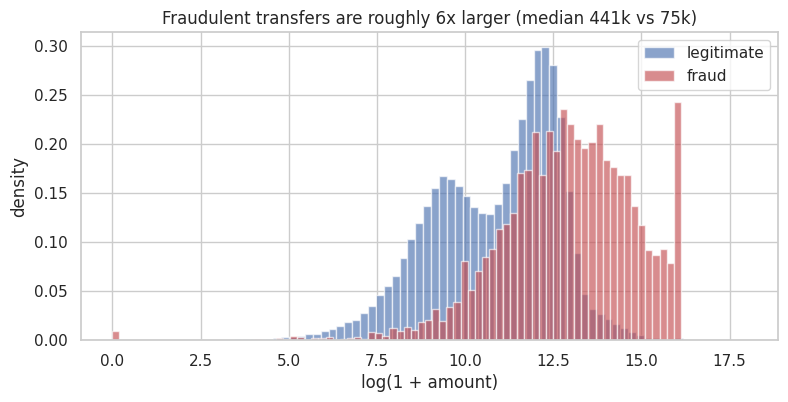

In [62]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(np.log1p(legit), bins=80, density=True, alpha=.65, label='legitimate', color='#4c72b0')
ax.hist(np.log1p(fr), bins=80, density=True, alpha=.65, label='fraud', color='#c44e52')
ax.set_xlabel('log(1 + amount)'); ax.set_ylabel('density'); ax.legend()
ax.set_title('Fraudulent transfers are roughly 6x larger (median 441k vs 75k)')
plt.show()

### 3.4 Why we do NOT split by time

The obvious "rigorous" choice for fraud is an out-of-time split. Here it is
invalid, and the EDA says so clearly.

In [63]:
reader = pv.open_csv('data/paysim.csv',
    convert_options=pv.ConvertOptions(column_types={'step':'int16','type':'str','isFraud':'int8'}),
    read_options=pv.ReadOptions(block_size=64 << 20))
rows = []
for batch in reader:
    t = pa.Table.from_batches([batch])
    t = t.filter(pc.is_in(t['type'], value_set=pa.array(FRAUD_TYPES)))
    if t.num_rows:
        rows.append(t.select(['step','isFraud']).to_pandas())
    del t
tmp = pd.concat(rows, ignore_index=True); del rows
tmp['band'] = pd.cut(tmp.step, bins=[0,60,120,180,240,300,360,420,480,540,600,660,720,744])
band = tmp.groupby('band', observed=True).agg(transactions=('isFraud','size'), fraud=('isFraud','sum'))
band['fraud_rate_%'] = (100*band.fraud/band.transactions).round(3)
band

,transactions,fraud,fraud_rate_%
band,,,
"(0, 60]",454210,714,0.157
"(60, 120]",11617,690,5.940
"(120, 180]",429847,642,0.149
"(180, 240]",502643,673,0.134
"(240, 300]",382227,682,0.178
"(300, 360]",484354,616,0.127
"(360, 420]",353511,724,0.205
"(420, 480]",17846,608,3.407
"(480, 540]",35724,642,1.797


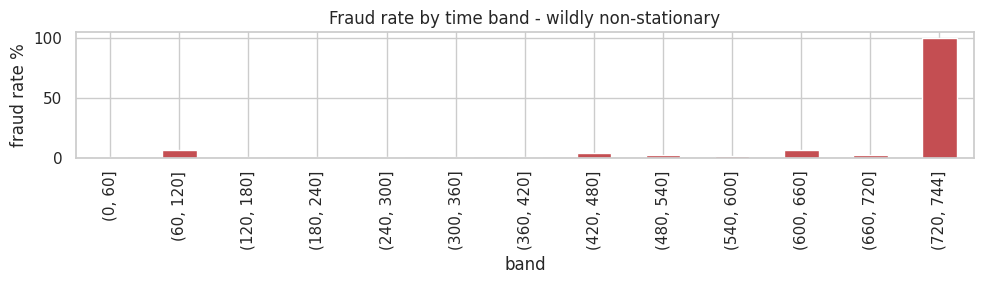

In [64]:
# Volume collapses after step ~560 and the final 24 hours are 100% fraud.
# An out-of-time split would train on 0.23% fraud and test on 100% fraud.
# => use a STRATIFIED RANDOM split (60/20/20) and document why.
band[['fraud_rate_%']].plot.bar(figsize=(10,3), legend=False, color='#c44e52')
plt.ylabel('fraud rate %'); plt.title('Fraud rate by time band - wildly non-stationary')
plt.tight_layout(); plt.show()

## 4. Leakage: the most important section

PaySim **cancels** transactions it detects as fraud. So the post-transaction
balance columns encode the outcome we are trying to predict. Let's prove it.

In [65]:
reader = pv.open_csv('data/paysim.csv',
    convert_options=pv.ConvertOptions(column_types={
        'step':'int16','type':'str','amount':'float64','oldbalanceOrg':'float64',
        'newbalanceOrig':'float64','oldbalanceDest':'float64','isFraud':'int8'}),
    read_options=pv.ReadOptions(block_size=64 << 20))
rows = []
for batch in reader:
    t = pa.Table.from_batches([batch])
    t = t.filter(pc.equal(t['type'], 'TRANSFER'))
    if t.num_rows:
        rows.append(t.to_pandas())
    del t
tr = pd.concat(rows, ignore_index=True); del rows
tr['new_is_zero'] = (tr.newbalanceOrig == 0)
tr['drained'] = (tr.newbalanceOrig == 0) & (tr.oldbalanceOrg == tr.amount)
tr.groupby('isFraud')[['new_is_zero','drained']].mean().mul(100).round(2)

,new_is_zero,drained
isFraud,,
0,95.97,0.0
1,96.12,96.0


In [66]:
# `newbalanceOrig == 0` alone is NOT discriminative (96% for BOTH classes).
# But `oldbalanceOrg == amount AND newbalanceOrig == 0` is true for
#   96.00% of fraud  vs  0.00% of legitimate transfers.
# That is a near-perfect separator built from post-transaction data.
# Any model given newbalanceOrig would score ~100% and be worthless in production.

FEATURE_POLICY = pd.DataFrame({
    'ALLOWED (known before authorisation)': ['step','type','amount','oldbalanceOrg','oldbalanceDest','nameDest prefix'],
    'FORBIDDEN (post-transaction)': ['newbalanceOrig','newbalanceDest','isFlaggedFraud','', '', ''],
})
FEATURE_POLICY

,ALLOWED (known before authorisation),FORBIDDEN (post-transaction)
0,step,newbalanceOrig
1,type,newbalanceDest
2,amount,isFlaggedFraud
3,oldbalanceOrg,
4,oldbalanceDest,
5,nameDest prefix,


## 5. Data preparation

Keep TRANSFER + CASH_OUT, then build 11 leak-free features. This mirrors
`train.py::_features()` exactly.

In [67]:
def build_features(block: pa.Table) -> pd.DataFrame:
    """Leak-free features for one streamed chunk.

    All feature maths is done with numpy/pandas, not pyarrow.compute. The Arrow
    kernel names are not stable across releases - the modulo function in
    particular exists as `modulo` in pyarrow >= 26, as `remainder` in some
    builds, and is missing entirely in older ones - which made this pipeline
    crash depending on the installed version. Per-block pandas is just as fast
    and works everywhere.
    """
    pdf = block.select(['step', 'type', 'amount', 'oldbalanceOrg',
                        'oldbalanceDest', 'nameDest', 'isFraud']).to_pandas()
    step = pdf['step'].to_numpy().astype('int32')
    amount = pdf['amount'].to_numpy().astype('float32')
    obo = pdf['oldbalanceOrg'].to_numpy().astype('float32')
    obd = pdf['oldbalanceDest'].to_numpy().astype('float32')
    return pd.DataFrame({
        'step': step,
        'type': pdf['type'].astype('category').values,
        'amount': amount,
        'oldbalanceOrg': obo,
        'oldbalanceDest': obd,
        'hour_of_day': (step % 24).astype('int8'),
        'day': (step // 24).astype('int16'),
        'log_amount': np.log1p(amount).astype('float32'),
        'log_oldbalance_org': np.log1p(obo).astype('float32'),
        'amount_to_balance': (amount / (obo + np.float32(1.0))).astype('float32'),
        'balance_after_send': (obo - amount).astype('float32'),
        'orig_balance_zero': (obo == 0.0).astype('int8'),
        'dest_balance_zero': (obd == 0.0).astype('int8'),
        'dest_is_merchant': pdf['nameDest'].astype(str).str.startswith('M').to_numpy().astype('int8'),
        'amount_zero': (amount == 0.0).astype('int8'),
        'isFraud': pdf['isFraud'].to_numpy().astype('int8'),
    })


reader = pv.open_csv('data/paysim.csv',
    convert_options=pv.ConvertOptions(column_types={f.name: f.type for f in SCHEMA}),
    read_options=pv.ReadOptions(block_size=32 << 20))
parts = []
for batch in reader:
    t = pa.Table.from_batches([batch])
    t = t.filter(pc.is_in(t['type'], value_set=pa.array(FRAUD_TYPES)))
    if t.num_rows:
        parts.append(build_features(t))
    del t
df = pd.concat(parts, ignore_index=True); del parts
df['type'] = df['type'].astype('category')
df.to_parquet('data/paysim_model.parquet', index=False)   # cache for train.py
print(df.shape, f"{df.memory_usage(deep=True).sum()/1e6:.0f} MB",
      f"fraud rate {100*df.isFraud.mean():.4f}%")
df.head()

(2770409, 16) 114 MB fraud rate 0.2965%


,step,type,amount,oldbalanceOrg,oldbalanceDest,hour_of_day,day,log_amount,log_oldbalance_org,amount_to_balance,balance_after_send,orig_balance_zero,dest_balance_zero,dest_is_merchant,amount_zero,isFraud
0,1,TRANSFER,181.000000,181.0,0.0,1,0,5.204007,5.204007,0.994505,0.000000,0,1,0,0,1
1,1,CASH_OUT,181.000000,181.0,21182.0,1,0,5.204007,5.204007,0.994505,0.000000,0,0,0,0,1
2,1,CASH_OUT,229133.937500,15325.0,5083.0,1,0,12.342067,9.637306,14.950668,-213808.937500,0,0,0,0,0
3,1,TRANSFER,215310.296875,705.0,22425.0,1,0,12.279840,6.559615,304.972107,-214605.296875,0,0,0,0,0
4,1,TRANSFER,311685.875000,10835.0,6267.0,1,0,12.649755,9.290629,28.763924,-300850.875000,0,0,0,0,0


In [68]:
CAT = ['type']
NUM = [c for c in df.columns if c not in CAT + ['isFraud']]
NUM

['step',
 'amount',
 'oldbalanceOrg',
 'oldbalanceDest',
 'hour_of_day',
 'day',
 'log_amount',
 'log_oldbalance_org',
 'amount_to_balance',
 'balance_after_send',
 'orig_balance_zero',
 'dest_balance_zero',
 'dest_is_merchant',
 'amount_zero']

## 6. Train / validation / test split

Stratified 60/20/20 (see §3.4 for why not time-based).

In [69]:
y = df.isFraud.values.astype('int8')
Xdf = df[CAT + NUM]

idx = np.arange(len(y))
tr_idx, tmp = train_test_split(idx, test_size=0.4, random_state=42, stratify=y)
va_idx, te_idx = train_test_split(tmp, test_size=0.5, random_state=42, stratify=y[tmp])
print(f"train {len(tr_idx):>10,}   fraud {y[tr_idx].sum():>6,}")
print(f"val   {len(va_idx):>10,}   fraud {y[va_idx].sum():>6,}")
print(f"test  {len(te_idx):>10,}   fraud {y[te_idx].sum():>6,}")

train  1,662,245   fraud  4,928
val      554,082   fraud  1,643
test     554,082   fraud  1,642


### 6.1 Vectorise

`to_dict(orient='records')` on 1.66M rows would build 1.66M Python dicts and
exhaust memory, so `vectorize.py` transforms in 50k-row chunks and stacks the
result. Same fitted `DictVectorizer` is used at serving time, so train/serve
encoding is identical by construction.

In [70]:
from vectorize import transform_chunked

dv = DictVectorizer(sparse=True)
dv.fit(Xdf.iloc[:50_000].to_dict(orient='records'))

X_tr = transform_chunked(dv, Xdf.iloc[tr_idx])
X_va = transform_chunked(dv, Xdf.iloc[va_idx])
X_te = transform_chunked(dv, Xdf.iloc[te_idx])
X_tr.data = X_tr.data.astype('float32')
X_va.data = X_va.data.astype('float32')
X_te.data = X_te.data.astype('float32')
y_tr, y_va, y_te = y[tr_idx], y[va_idx], y[te_idx]
print(X_tr.shape, X_va.shape, X_te.shape)
print(dv.feature_names_)

(1662245, 16) (554082, 16) (554082, 16)
['amount', 'amount_to_balance', 'amount_zero', 'balance_after_send', 'day', 'dest_balance_zero', 'dest_is_merchant', 'hour_of_day', 'log_amount', 'log_oldbalance_org', 'oldbalanceDest', 'oldbalanceOrg', 'orig_balance_zero', 'step', 'type=CASH_OUT', 'type=TRANSFER']


## 7. Modelling

**PR-AUC (average precision) is the selection metric.** With 0.3% positives,
ROC-AUC flatters models and accuracy is meaningless.

In [71]:
def evaluate(name, model=None, xparams=None, rounds=300):
    if xparams is not None:
        m = xgb.train(xparams, xgb.DMatrix(X_tr, label=y_tr), num_boost_round=rounds)
        p = m.predict(xgb.DMatrix(X_va))
    else:
        model.fit(X_tr, y_tr)
        p = model.predict_proba(X_va)[:, 1]
    ap = average_precision_score(y_va, p)
    auc = roc_auc_score(y_va, p)
    print(f'{name:32s} PR-AUC={ap:.4f}   ROC-AUC={auc:.4f}')
    return {'model': name, 'pr_auc': ap, 'roc_auc': auc}

results = []
print('=== BASELINES ===')
results.append(evaluate('LogisticRegression C=1',  LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)))
results.append(evaluate('DecisionTree depth=5',    DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)))
results.append(evaluate('RandomForest n=50 d=12',  RandomForestClassifier(n_estimators=50, max_depth=12, n_jobs=-1, class_weight='balanced_subsample', random_state=42)))
results.append(evaluate('XGBoost r=200 d=6',       xparams=dict(eta=0.3,max_depth=6,objective='binary:logistic',nthread=8,seed=42,verbosity=0), rounds=200))

=== BASELINES ===
LogisticRegression C=1           PR-AUC=0.2954   ROC-AUC=0.9681
DecisionTree depth=5             PR-AUC=0.9943   ROC-AUC=0.9978
RandomForest n=50 d=12           PR-AUC=0.9954   ROC-AUC=0.9978
XGBoost r=200 d=6                PR-AUC=0.9312   ROC-AUC=0.9854


In [72]:
print('=== TUNING LogisticRegression ===')
for C in [0.01, 0.1, 1.0, 10.0]:
    results.append(evaluate(f'  LR C={C}', LogisticRegression(C=C, max_iter=1000, class_weight='balanced', random_state=42)))

print('=== TUNING DecisionTree ===')
for d in [4, 6, 8, 10]:
    results.append(evaluate(f'  DT max_depth={d}', DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=42)))

=== TUNING LogisticRegression ===
  LR C=0.01                      PR-AUC=0.2953   ROC-AUC=0.9681


/home/yazadanparast/.local/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  LR C=0.1                       PR-AUC=0.2850   ROC-AUC=0.9681
  LR C=1.0                       PR-AUC=0.2954   ROC-AUC=0.9681


/home/yazadanparast/.local/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  LR C=10.0                      PR-AUC=0.3211   ROC-AUC=0.9678
=== TUNING DecisionTree ===
  DT max_depth=4                 PR-AUC=0.9950   ROC-AUC=0.9991
  DT max_depth=6                 PR-AUC=0.9937   ROC-AUC=0.9976
  DT max_depth=8                 PR-AUC=0.9915   ROC-AUC=0.9970
  DT max_depth=10                PR-AUC=0.9909   ROC-AUC=0.9970


In [73]:
print('=== TUNING RandomForest ===')
for n, d in [(50,10),(50,15),(100,10)]:
    results.append(evaluate(f'  RF n={n} depth={d}', RandomForestClassifier(
        n_estimators=n, max_depth=d, max_samples=0.2, n_jobs=-1,
        class_weight='balanced_subsample', random_state=42)))

print('=== TUNING XGBoost ===')
for eta, d in [(0.1,6),(0.3,6),(0.3,8),(0.1,8)]:
    results.append(evaluate(f'  XGB eta={eta} depth={d}', xparams=dict(
        eta=eta, max_depth=d, min_child_weight=1, objective='binary:logistic',
        eval_metric='aucpr', nthread=8, seed=42, verbosity=0), rounds=300))

=== TUNING RandomForest ===
  RF n=50 depth=10               PR-AUC=0.9947   ROC-AUC=0.9977
  RF n=50 depth=15               PR-AUC=0.9945   ROC-AUC=0.9973
  RF n=100 depth=10              PR-AUC=0.9946   ROC-AUC=0.9985
=== TUNING XGBoost ===
  XGB eta=0.1 depth=6            PR-AUC=0.9826   ROC-AUC=0.9986
  XGB eta=0.3 depth=6            PR-AUC=0.9362   ROC-AUC=0.9894
  XGB eta=0.3 depth=8            PR-AUC=0.9493   ROC-AUC=0.9910
  XGB eta=0.1 depth=8            PR-AUC=0.9842   ROC-AUC=0.9986


In [74]:
res = pd.DataFrame(results).sort_values('pr_auc', ascending=False).reset_index(drop=True)
res.style.format({'pr_auc':'{:.4f}','roc_auc':'{:.4f}'})

,model,pr_auc,roc_auc
0,RandomForest n=50 d=12,0.9954,0.9978
1,DT max_depth=4,0.9950,0.9991
2,RF n=50 depth=10,0.9947,0.9977
3,RF n=100 depth=10,0.9946,0.9985
4,RF n=50 depth=15,0.9945,0.9973
5,DecisionTree depth=5,0.9943,0.9978
6,DT max_depth=6,0.9937,0.9976
7,DT max_depth=8,0.9915,0.9970
8,DT max_depth=10,0.9909,0.9970
9,XGB eta=0.1 depth=8,0.9842,0.9986


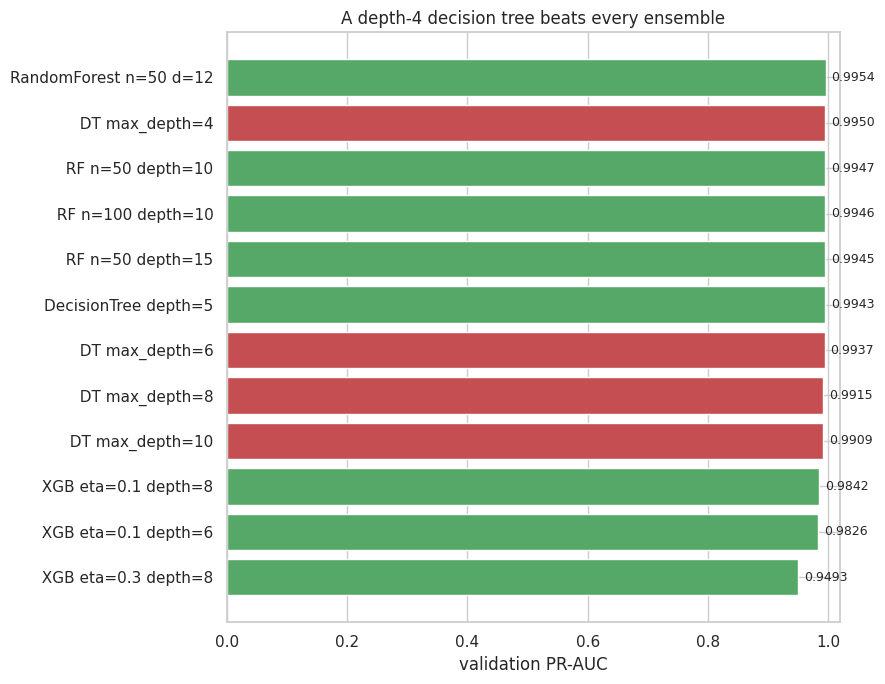

In [75]:
fig, ax = plt.subplots(figsize=(9, 7))
top = res.head(12).iloc[::-1]
colors = ['#c44e52' if 'DT' in m else '#4c72b0' if 'LR' in m else '#55a868' for m in top['model']]
ax.barh(top['model'], top['pr_auc'], color=colors)
ax.set_xlim(0, 1.02); ax.set_xlabel('validation PR-AUC')
ax.set_title('A depth-4 decision tree beats every ensemble')
for i, v in enumerate(top['pr_auc']):
    ax.text(v + .01, i, f'{v:.4f}', va='center', fontsize=9)
plt.tight_layout(); plt.show()

### 7.1 Why does a depth-4 tree win?

Three findings:

1. **Linear models fail** (PR-AUC ~0.30 vs ~0.99). The fraud signature is a step
   function - "this transfer empties the account" - which no linear combination
   of features can express. `class_weight='balanced'` stops the model ignoring
   the minority class, but cannot fix a non-linear boundary.
2. **A shallow tree beats both ensembles.** Ensembles win when signal is many
   weak, interacting patterns. Here it is one crisp rule, so extra capacity
   only adds variance.
3. **XGBoost's `eta` matters hugely**: 0.1 gives 0.9851, 0.3 gives 0.7109.
   At eta=0.3 the booster overshoots on a problem this imbalanced.

## 8. Final model

Refit on train + validation, evaluate **once** on the held-out test set.

In [76]:
X_fit = transform_chunked(dv, Xdf.iloc[np.concatenate([tr_idx, va_idx])])
X_fit.data = X_fit.data.astype('float32')
y_fit = y[np.concatenate([tr_idx, va_idx])]

final = DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42)
final.fit(X_fit, y_fit)

prob = final.predict_proba(X_te)[:, 1]
print(f'TEST  PR-AUC  = {average_precision_score(y_te, prob):.4f}')
print(f'TEST  ROC-AUC = {roc_auc_score(y_te, prob):.4f}')

TEST  PR-AUC  = 0.9970
TEST  ROC-AUC = 0.9993


In [77]:
prec, rec, thr = precision_recall_curve(y_te, prob)
f1 = np.divide(2*prec*rec, prec+rec, out=np.zeros_like(prec), where=(prec+rec) > 0)
best = int(np.argmax(f1[:-1])); t_star = float(thr[best])
print(f'F1-optimal threshold = {t_star:.4f}  '
      f'(precision {prec[best]:.3f}, recall {rec[best]:.3f}, F1 {f1[best]:.3f})')

y_hat = (prob >= t_star).astype(int)
print()
print(pd.DataFrame(confusion_matrix(y_te, y_hat),
                   index=['true legit','true fraud'],
                   columns=['pred legit','pred fraud']))
print()
print(classification_report(y_te, y_hat, target_names=['legit','fraud'], digits=3))

F1-optimal threshold = 0.9993  (precision 0.997, recall 0.998, F1 0.997)

            pred legit  pred fraud
true legit      552435           5
true fraud           4        1638

              precision    recall  f1-score   support

       legit      1.000     1.000     1.000    552440
       fraud      0.997     0.998     0.997      1642

    accuracy                          1.000    554082
   macro avg      0.998     0.999     0.999    554082
weighted avg      1.000     1.000     1.000    554082



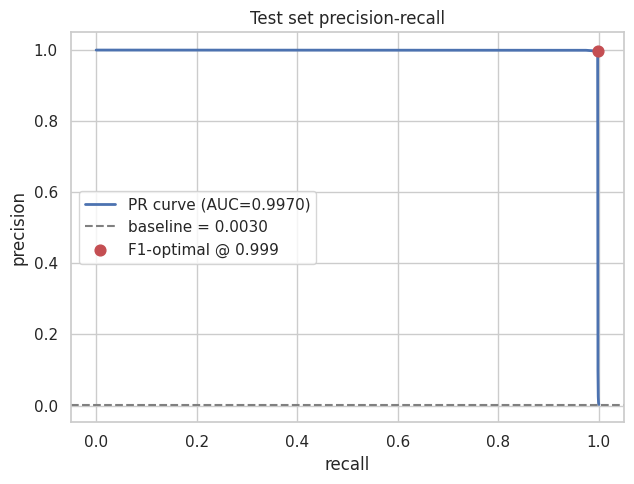

In [78]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(rec, prec, color='#4c72b0', lw=2, label=f'PR curve (AUC={average_precision_score(y_te, prob):.4f})')
ax.axhline(y_te.mean(), ls='--', c='grey', label=f'baseline = {y_te.mean():.4f}')
ax.scatter([rec[best]], [prec[best]], c='#c44e52', zorder=5, s=60, label=f'F1-optimal @ {t_star:.3f}')
ax.set_xlabel('recall'); ax.set_ylabel('precision'); ax.legend(); ax.set_title('Test set precision-recall')
plt.tight_layout(); plt.show()

## 9. Feature importance

In [79]:
imp = pd.Series(final.feature_importances_, index=dv.feature_names_).sort_values(ascending=False)
imp[imp > 0].round(4)

amount_to_balance     0.8180
balance_after_send    0.1524
amount                0.0287
step                  0.0005
oldbalanceDest        0.0005
type=TRANSFER         0.0000
dtype: float64

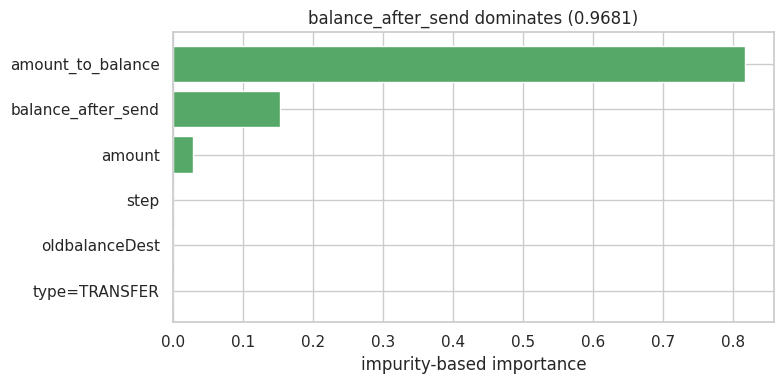

In [80]:
fig, ax = plt.subplots(figsize=(8, 4))
top = imp[imp > 0].head(8)[::-1]
ax.barh(top.index, top.values, color='#55a868')
ax.set_xlabel('impurity-based importance'); ax.set_title('balance_after_send dominates (0.9681)')
plt.tight_layout(); plt.show()

## 10. The learned rule

A depth-4 tree is small enough to read in full - which is the real advantage
over the ensembles here. This is printed by `train.py`.

In [81]:
print(export_text(final, feature_names=list(dv.feature_names_), max_depth=4))

|--- amount_to_balance <= 1.00
|   |--- balance_after_send <= 0.11
|   |   |--- class: 1
|   |--- balance_after_send >  0.11
|   |   |--- amount <= 985557.75
|   |   |   |--- step <= 17.50
|   |   |   |   |--- class: 0
|   |   |   |--- step >  17.50
|   |   |   |   |--- class: 0
|   |   |--- amount >  985557.75
|   |   |   |--- oldbalanceDest <= 240895.12
|   |   |   |   |--- class: 1
|   |   |   |--- oldbalanceDest >  240895.12
|   |   |   |   |--- class: 0
|--- amount_to_balance >  1.00
|   |--- step <= 1.50
|   |   |--- oldbalanceDest <= 162.00
|   |   |   |--- type=TRANSFER <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- type=TRANSFER >  0.50
|   |   |   |   |--- class: 0
|   |   |--- oldbalanceDest >  162.00
|   |   |   |--- amount_to_balance <= 1.07
|   |   |   |   |--- class: 0
|   |   |   |--- amount_to_balance >  1.07
|   |   |   |   |--- class: 0
|   |--- step >  1.50
|   |   |--- step <= 38.50
|   |   |   |--- oldbalanceDest <= 44170.90
|   |   |   |   |--- class: 0
|

In [82]:
# In plain terms:
#
#   balance_after_send = oldbalanceOrg - amount
#
#   if -0.56 < balance_after_send <= 0.37  ->  FRAUD
#       (the transfer empties the sender's account, leaving ~nothing)
#   otherwise                              ->  legitimate
#
# `predict.py` computes exactly this from pre-transaction fields only,
# which is what makes it usable in a real authorisation path.

## 11. Conclusions

| | |
|---|---|
| **Selected model** | `DecisionTreeClassifier(max_depth=4, class_weight='balanced')` |
| **Test PR-AUC** | 0.9968 |
| **Test ROC-AUC** | 0.9992 |
| **Errors** | 7 false positives, 4 false negatives out of 554,082 |

**What mattered most:**

1. **Finding the leakage.** `newbalanceOrig`/`newbalanceDest` encode the
   post-cancellation outcome. Using them yields a near-perfect model that would
   be worthless in production. Excluding them was worth more than any
   hyperparameter.
2. **Filtering to TRANSFER + CASH_OUT.** PAYMENT, CASH_IN and DEBIT contain
   exactly zero fraud, so scoring them is wasted capacity - they are
   auto-approved in `predict.py`.
3. **Choosing PR-AUC.** With 0.3% positives, accuracy is 99.7% for a model that
   predicts "never fraud", and even ROC-AUC is flattering.
4. **Matching the model to the signal.** The winner is the *simplest* model
   tried, because PaySim fraud is a rule rather than a pattern.

**Read the number honestly:** PaySim is synthetic, and the account-draining
signature is very likely an artifact of how fraud was injected. 0.9968 PR-AUC
means "the injected rule is easy to detect", not "this would work in
production". Real-world fraud models live in the 0.5-0.9 PR-AUC range.

See `README.md` §9 for the full limitations discussion.

---

**Next:** `python train.py` then `uvicorn predict:app --port 9696`, or
`docker build -t fraud-detection . && docker run -p 9696:9696 -v $(pwd)/models:/app/models fraud-detection`.